# Model training, evaluation and comparisons



    This read-only notebook loads a portable snapshot of real epoch/evaluation
    reports. It does not train or evaluate a model. Missing test results are
    reported as unavailable, never as zeros. Checkpoints are selected by minimum
    validation cross-entropy. ASL Citizen official splits are signer-disjoint.

    Models differ in input representation and capacity; this is not a pure
    architecture-only ablation. Offline scores do not establish webcam accuracy.
    The existing held-out test has been seen during project development; no
    model settings are selected in this notebook from its scores.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

def find_snapshot():
    for folder in (Path.cwd(), *Path.cwd().parents):
        for relative in ('artifacts/experiment_snapshot.json', 'notebooks/artifacts/experiment_snapshot.json'):
            candidate = folder/relative
            if candidate.exists():
                return candidate
    raise FileNotFoundError('Keep the notebooks/artifacts folder beside these notebooks.')

SNAPSHOT_PATH = find_snapshot()
S = json.loads(SNAPSHOT_PATH.read_text(encoding='utf-8'))
M = S['models']
COLORS = {'gru_baseline':'#2878b5','gru_regularized':'#219653','gru64':'#e49320','stgcn':'#8e44ad'}
plt.rcParams.update({'figure.figsize':(11,5),'font.size':10,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,
                     'figure.constrained_layout.use':True})
def finish(title):
    plt.gcf().suptitle(title,fontsize=14,fontweight='bold')
    plt.show()
print('Snapshot:',S['generated_utc'])
print('ST-GCN final evaluation complete:',S['stgcn_complete'])
print('Read-only report: no training, extraction, downloads, webcam or weight updates.')

Snapshot: 2026-11-10T20:33:21.779173+00:00
ST-GCN final evaluation complete: True
Read-only report: no training, extraction, downloads, webcam or weight updates.


## Final result

        **ST-GCN training and frozen test evaluation completed successfully.**
        It trained for 49 epochs and selected epoch
        **39** using the lowest validation cross-entropy.

        - Test top-1: **57.25%**, versus 49.92% for
          the regularized GRU (**+7.33 percentage points**).
        - Test top-5: **82.32%**; macro F1: **56.74%**.
        - Evaluation covered **32,941 clips**, all 2,731 labels and
          11 official test signers. No weight updates or augmentation occurred.

        ### Selected checkpoint versus last epoch

        Epoch 39: validation top-1 **67.23%**,
        cross-entropy **1.39338**.
        Last epoch 49: validation top-1 **68.85%**,
        cross-entropy **1.44400**.
        Accuracy and cross-entropy measure different properties. A later epoch
        can have higher accuracy but worse loss. We retained the declared
        minimum-loss selection rule; the test result belongs to epoch
        39, not the last or highest-accuracy checkpoint.

### Independent export verification

            Streamed all 32,941 ordered prediction records
            against the official test index; rebuilt the confusion matrix and
            recomputed top-1/top-5, macro precision/recall/F1 and weighted F1.
            All matched the evaluation report and per-class/per-signer exports.
            Correct counts: **18,858 top-1** and
            **27,117 top-5**. The evaluated checkpoint
            hash and preserved GRU/archive hashes were unchanged. Cross-entropy
            was retained from the full-logit evaluator; it cannot be reconstructed
            completely from the exported five scores per clip.

## 1. Experiment inventory

| Model | Status | Committed epochs | Selected epoch | Parameters | Validation top-1 | Test top-1 |
| --- | --- | --- | --- | --- | --- | --- |
| GRU 256 baseline | completed | 33 | 23 | 1,489,835 | 55.73% | Not evaluated |
| GRU 256 regularized | completed | 47 | 37 | 1,489,835 | 61.06% | 49.92% |
| GRU 64 baseline | completed | 50 | 49 | 263,915 | 45.89% | Not evaluated |
| ST-GCN27 | completed | 49 | 39 | 3,788,165 | 67.23% | 57.25% |

For an ongoing run, selection is provisional among committed epochs. The 64-unit run used the original baseline settings; the regularized GRU used a different profile. ST-GCN uses selected XY graph nodes and temporal pooling.

## 2. Learning curves

    Every point is a committed epoch JSON, not a smoothed or fabricated value.
    Dotted selection markers show the lowest-validation-loss checkpoint.
    Training accuracy was measured while parameters changed, with dropout and
    training augmentation where enabled; validation uses fixed eval mode. Their
    gap is informative but is not a comparison of two clean fixed-model passes.

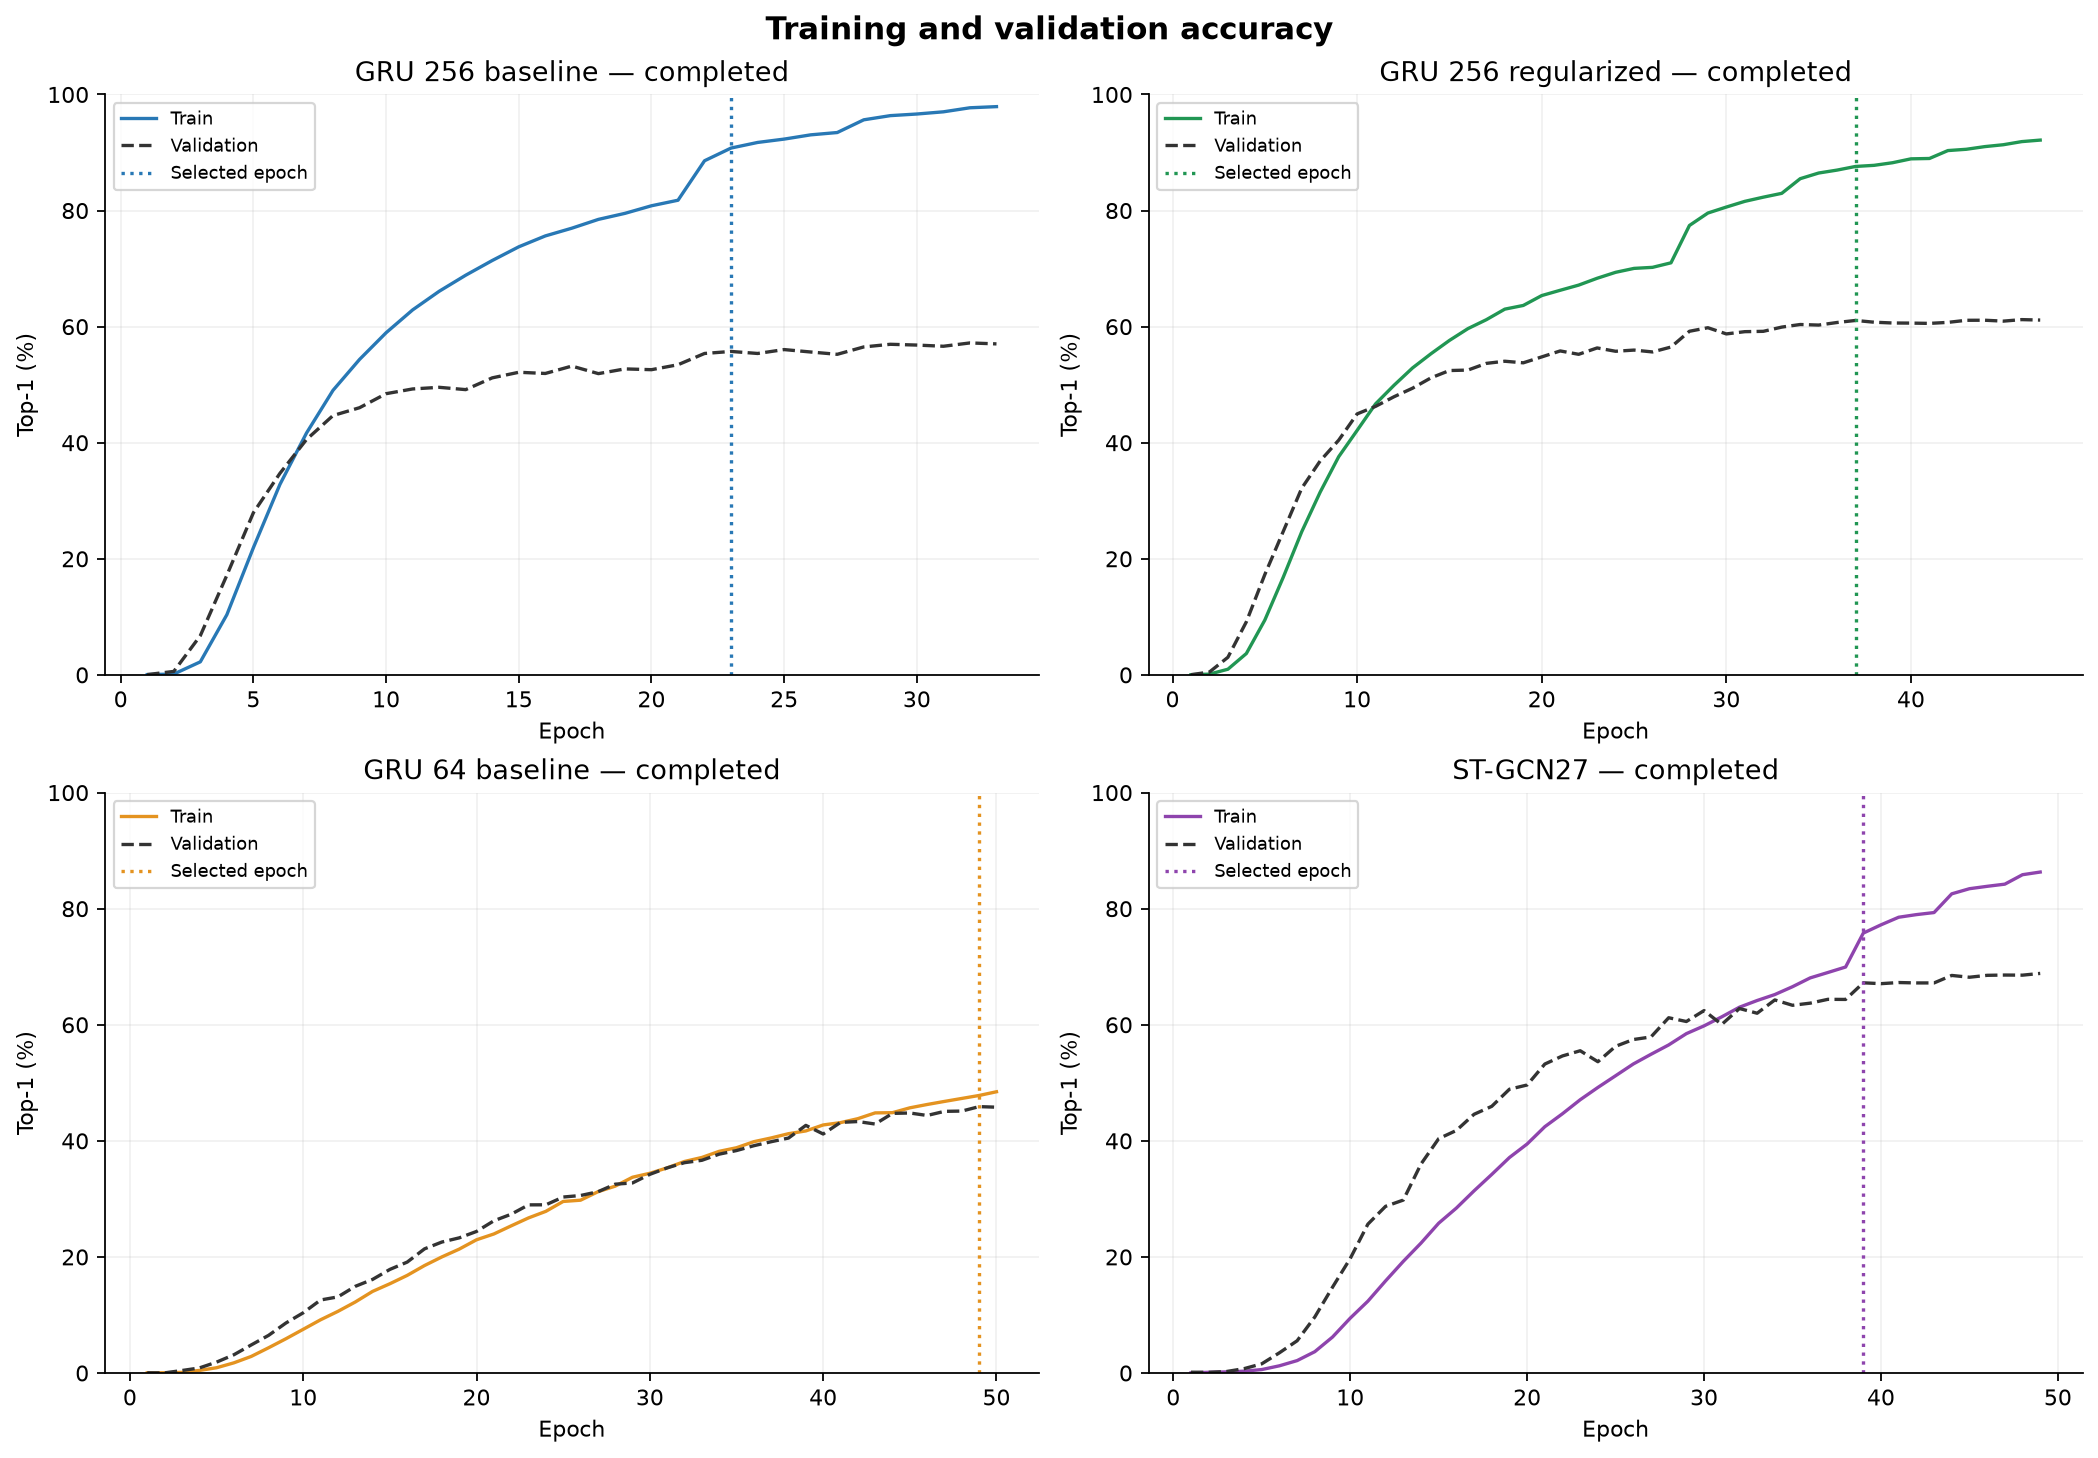

In [2]:
fig,axs=plt.subplots(2,2,figsize=(13,9))
for ax,(key,m) in zip(axs.flat,M.items()):
    h=m['history'];epochs=[r['epoch'] for r in h]
    ax.plot(epochs,[r['train']['top1']*100 for r in h],label='Train',color=COLORS[key])
    ax.plot(epochs,[r['val']['top1']*100 for r in h],'--',label='Validation',color='#333333')
    if m['selected']:ax.axvline(m['selected']['epoch'],ls=':',color=COLORS[key],label='Selected epoch')
    ax.set(title=m['label']+' — '+m['status'],xlabel='Epoch',ylabel='Top-1 (%)',ylim=(0,100))
    ax.legend(fontsize=8)
finish('Training and validation accuracy')

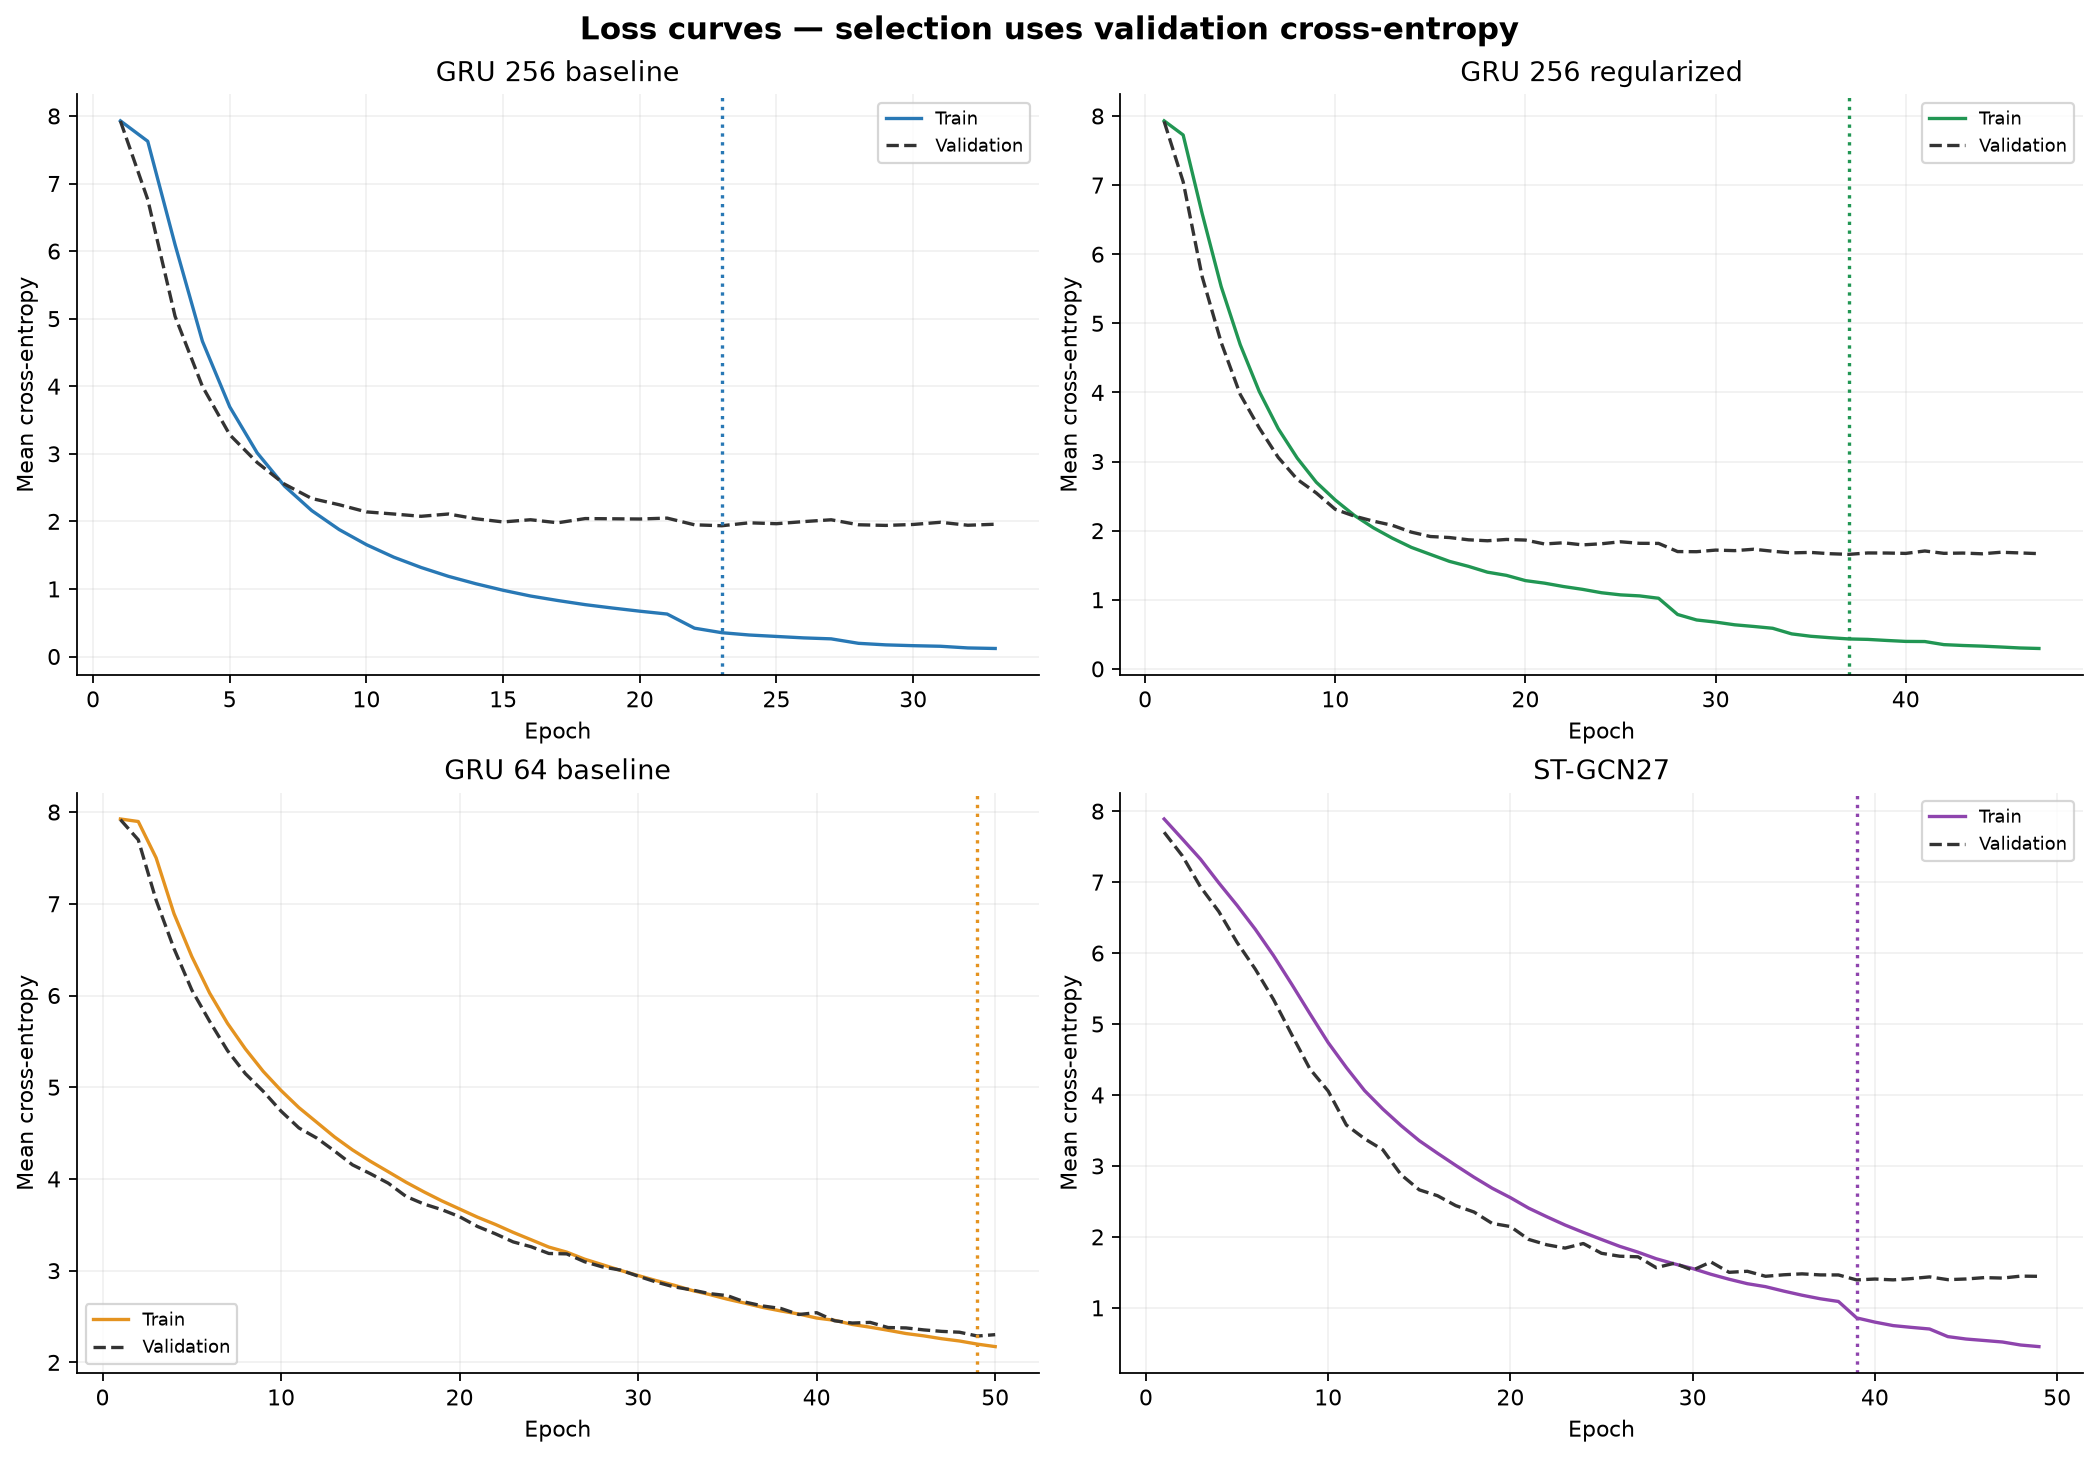

In [3]:
fig,axs=plt.subplots(2,2,figsize=(13,9))
for ax,(key,m) in zip(axs.flat,M.items()):
    h=m['history'];epochs=[r['epoch'] for r in h]
    ax.plot(epochs,[r['train']['loss'] for r in h],label='Train',color=COLORS[key])
    ax.plot(epochs,[r['val']['loss'] for r in h],'--',label='Validation',color='#333333')
    if m['selected']:ax.axvline(m['selected']['epoch'],ls=':',color=COLORS[key])
    ax.set(title=m['label'],xlabel='Epoch',ylabel='Mean cross-entropy');ax.legend(fontsize=8)
finish('Loss curves — selection uses validation cross-entropy')

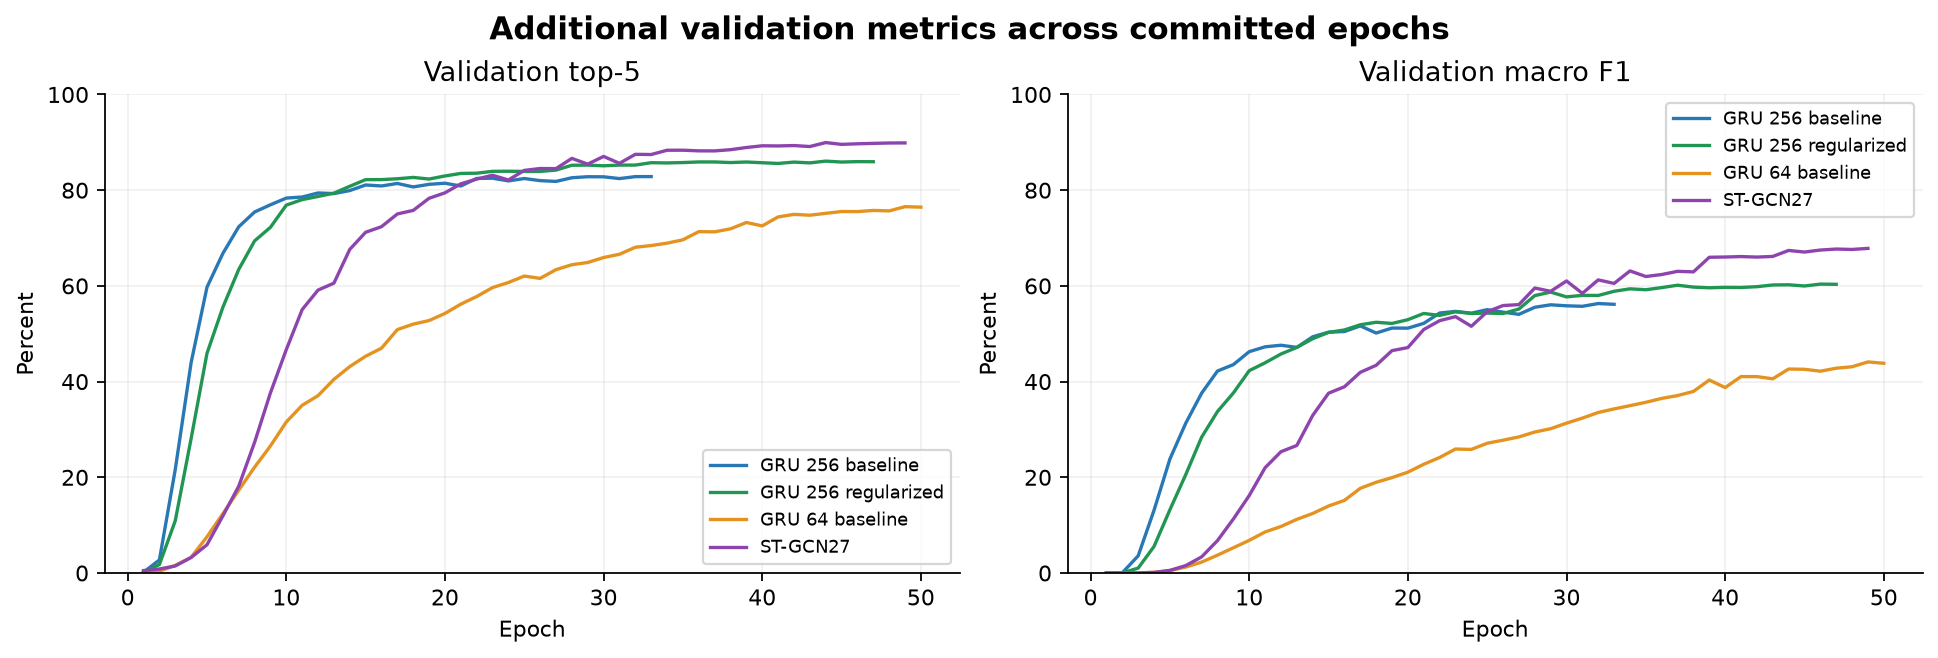

In [4]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
for key,m in M.items():
    h=m['history'];x=[r['epoch'] for r in h]
    axs[0].plot(x,[r['val']['top5']*100 for r in h],label=m['label'],color=COLORS[key])
    axs[1].plot(x,[r['val']['macro_f1']*100 for r in h],label=m['label'],color=COLORS[key])
for ax,title in zip(axs,('Validation top-5','Validation macro F1')):
    ax.set(xlabel='Epoch',ylabel='Percent',ylim=(0,100),title=title);ax.legend(fontsize=8)
finish('Additional validation metrics across committed epochs')

## 3. Metric definitions and selected-model comparison

    - **Top-1:** correct highest-score label / clips. **Top-5:** true label in
      five highest scores / clips; it does not mean the first displayed guess is correct.
    - **Precision:** TP/(TP+FP); **recall:** TP/(TP+FN); **F1:** harmonic mean
      of precision/recall, computed per class. Zero denominators return zero.
    - **Macro metrics:** unweighted mean across all 2,731 classes. Macro F1 is
      the mean of class F1 scores, not the harmonic mean of macro P and macro R.
    - **Weighted F1:** class F1 weighted by true support. **Cross-entropy:** mean
      negative log probability of the true class, computed from raw logits.

    Selection metrics below come from the same official validation split.
    Cross-validation fold scores use different partitions and are shown separately.

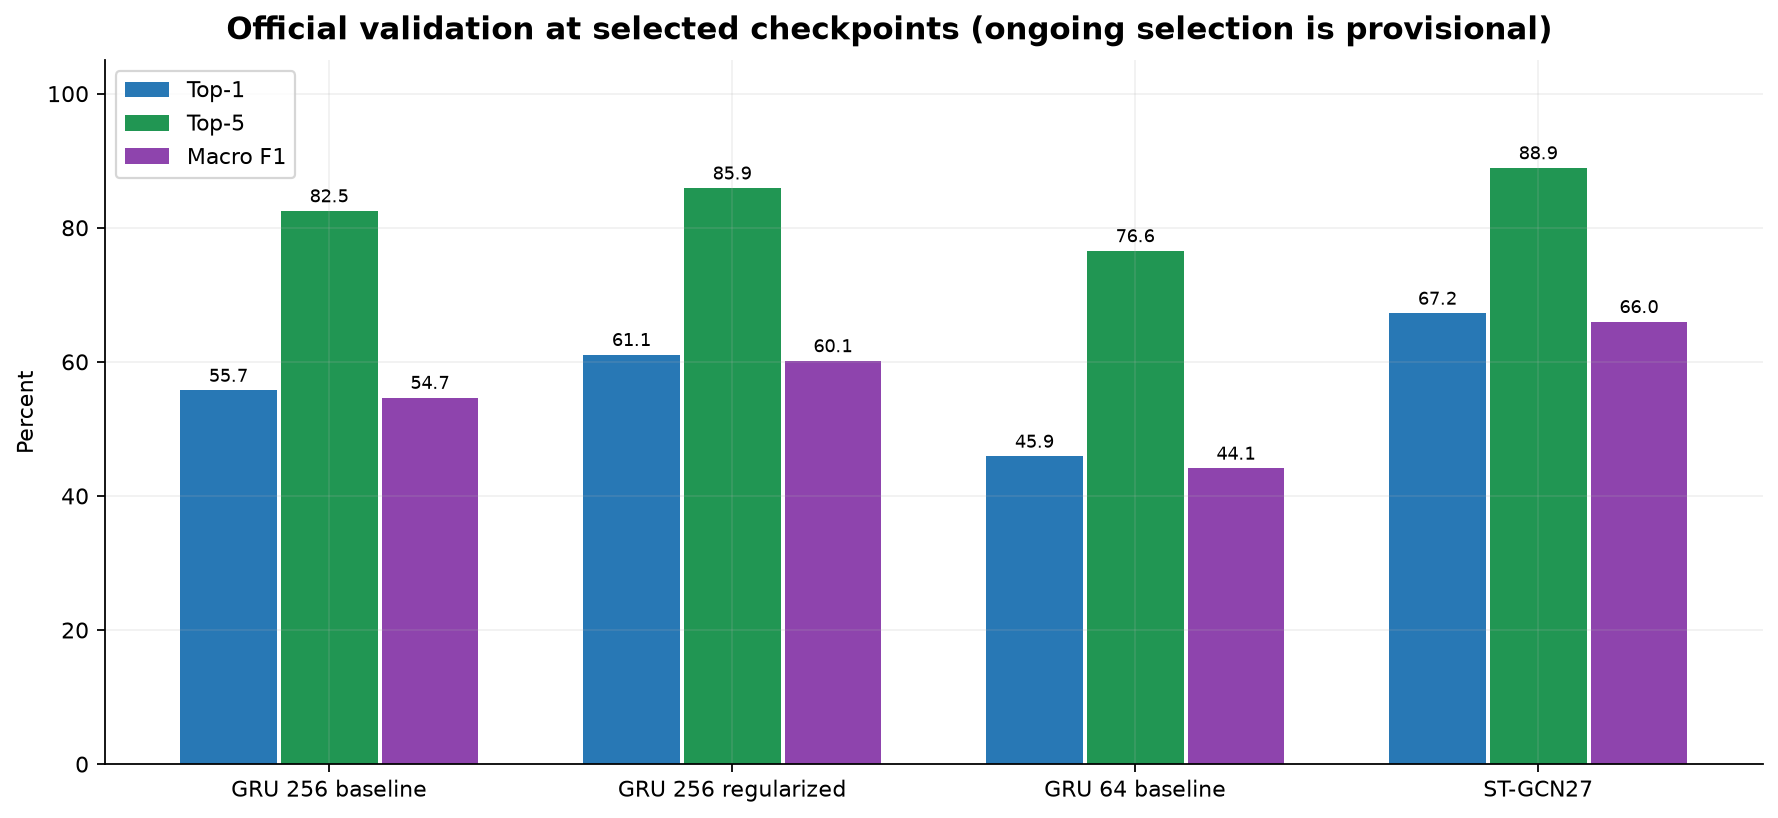

In [5]:
keys=[k for k,m in M.items() if m['selected']]
x=np.arange(len(keys));fig,ax=plt.subplots(figsize=(11,5))
for offset,metric,label,color in [(-.25,'top1','Top-1','#2878b5'),(0,'top5','Top-5','#219653'),(.25,'macro_f1','Macro F1','#8e44ad')]:
    values=[M[k]['selected']['val'][metric]*100 for k in keys]
    bars=ax.bar(x+offset,values,.24,label=label,color=color)
    ax.bar_label(bars,fmt='%.1f',padding=2,fontsize=8)
ax.set(xticks=x,xticklabels=[M[k]['label'] for k in keys],ylabel='Percent',ylim=(0,105))
ax.legend();finish('Official validation at selected checkpoints (ongoing selection is provisional)')

## 4. Development cross-validation

    Three signer-grouped folds used only the official training pool. Their
    holdouts also selected epochs, so this is development CV, not an independent
    nested-CV test. Fold standard deviation is not a confidence interval. The
    official validation split was subsequently used in a separate fresh refit.

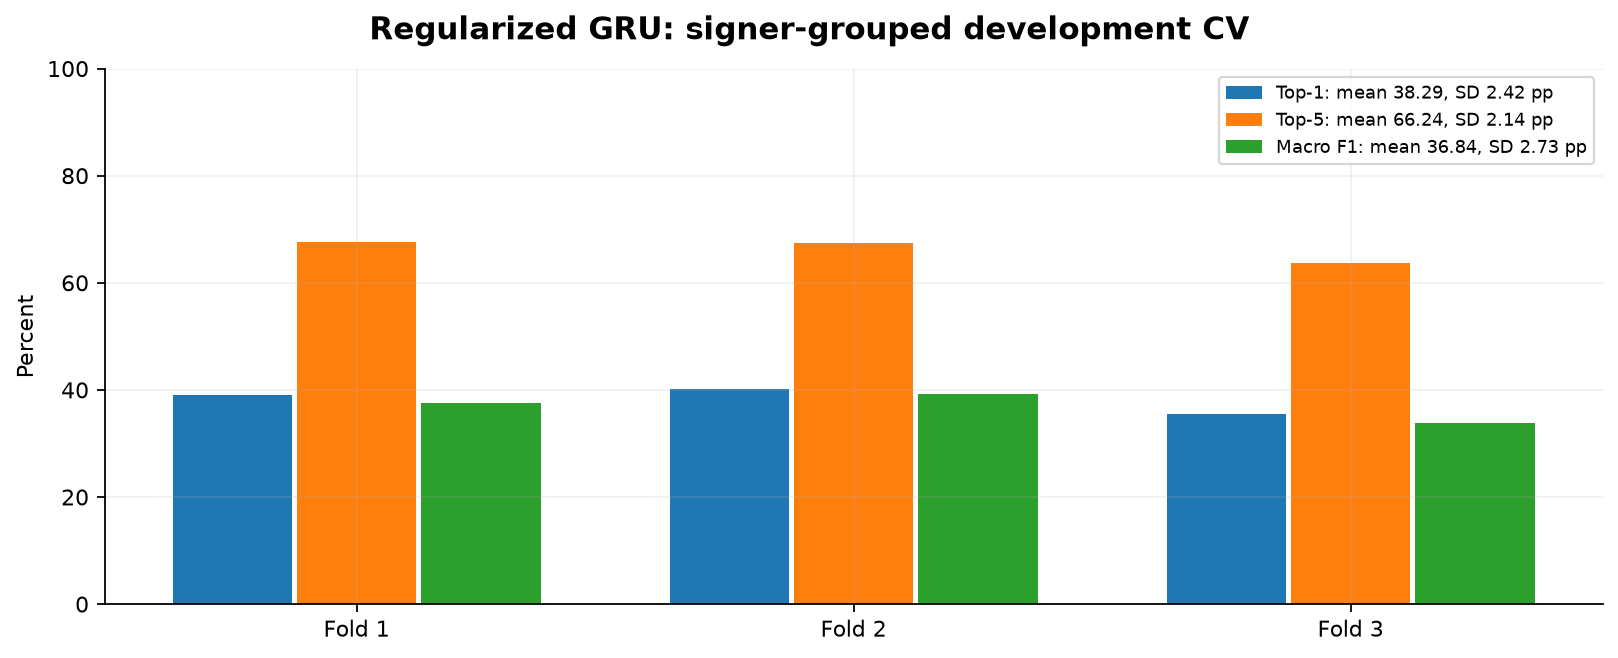

In [6]:
folds=S['cv']['folds'];x=np.arange(len(folds));fig,ax=plt.subplots(figsize=(10,4))
for offset,key,label in [(-.25,'top1','Top-1'),(0,'top5','Top-5'),(.25,'macro_f1','Macro F1')]:
    values=np.array([f['validation'][key]*100 for f in folds])
    ax.bar(x+offset,values,.24,label=f'{label}: mean {values.mean():.2f}, SD {values.std(ddof=1):.2f} pp')
ax.set(xticks=x,xticklabels=[f'Fold {f["fold"]+1}' for f in folds],ylabel='Percent',ylim=(0,100))
ax.legend(fontsize=8);finish('Regularized GRU: signer-grouped development CV')

## 5. Frozen official test evaluation

    Test inference uses eval/inference mode, no augmentation or weight updates;
    checkpoint identity is checked before/after. Only completed reports appear.
    The baseline and 64-unit GRUs have no test evaluation in the current record.
    Per-class and per-signer graphs describe the named test population.
    They do not quantify new-user webcam performance.

GRU 256 regularized : 32941 test clips | epoch 37
  top1 : 0.499226
  top5 : 0.762424
  macro_precision : 0.527607
  macro_recall : 0.499273
  macro_f1 : 0.494687
  weighted_f1 : 0.495543
  loss : 2.443036
ST-GCN27 : 32941 test clips | epoch 39
  top1 : 0.572478
  top5 : 0.823199
  macro_precision : 0.599806
  macro_recall : 0.573201
  macro_f1 : 0.567447
  weighted_f1 : 0.567642
  loss : 2.08828


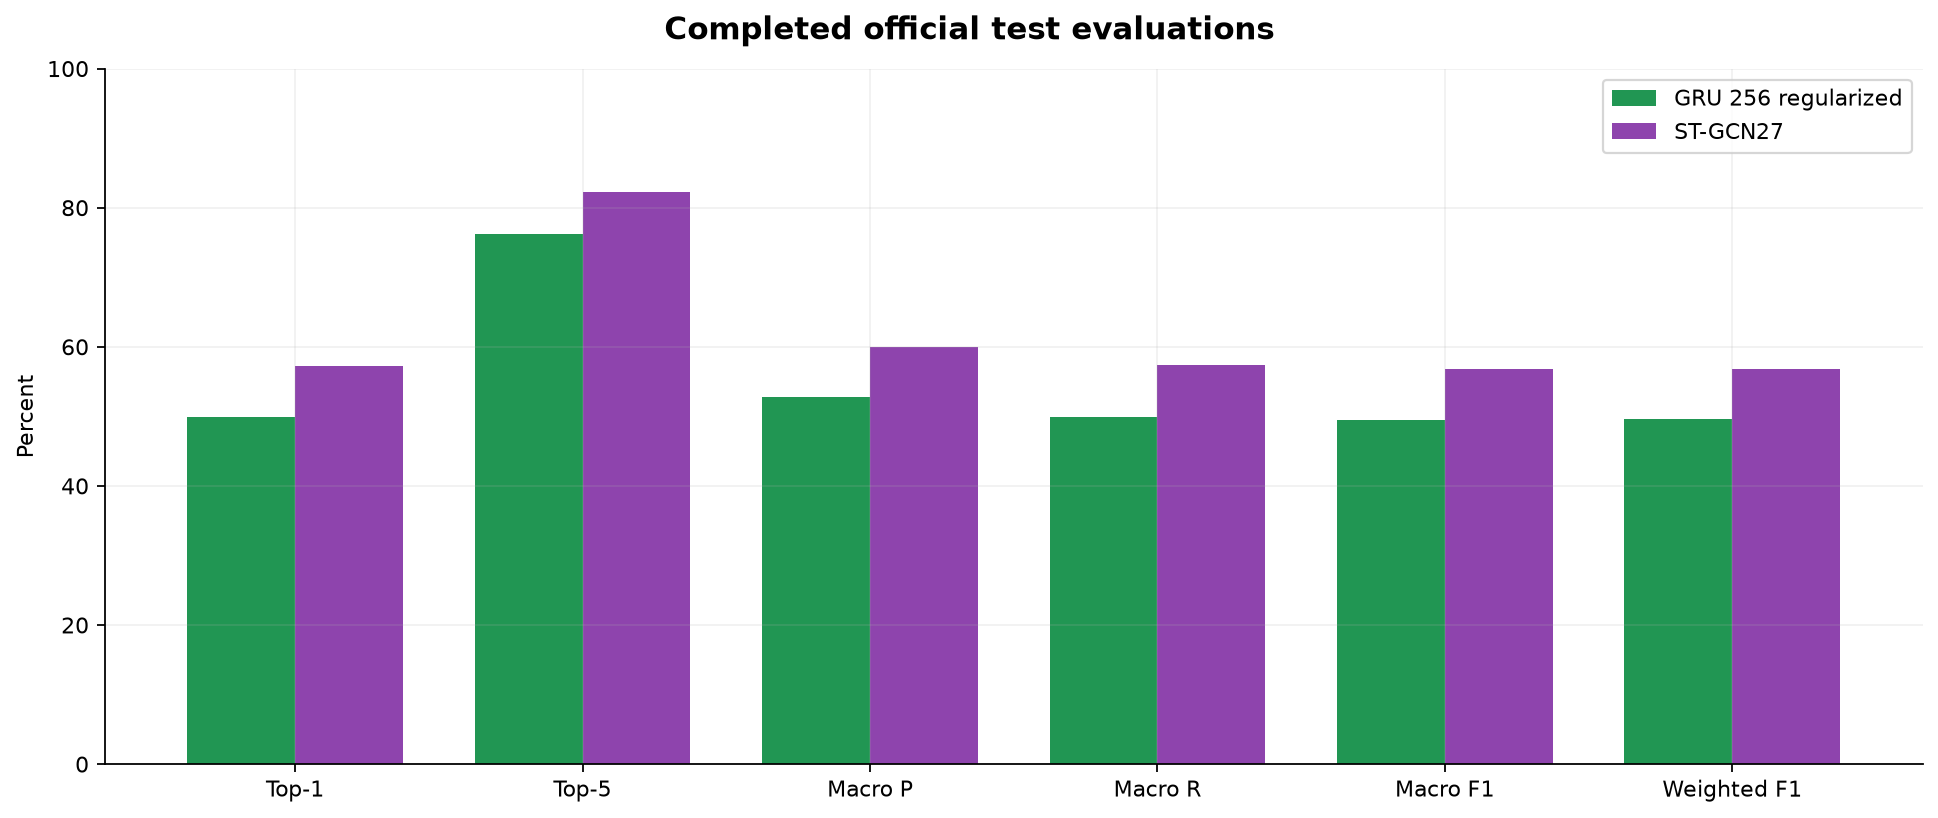

In [7]:
tested={k:m for k,m in M.items() if m.get('test') and m['test'].get('status')=='complete'}
for m in tested.values():
    t=m['test'];print(m['label'],':',t['metrics']['samples'],'test clips | epoch',t['checkpoint_epoch'])
    for key in ('top1','top5','macro_precision','macro_recall','macro_f1','weighted_f1','loss'):
        print(' ',key,':',round(t['metrics'][key],6))
metrics=['top1','top5','macro_precision','macro_recall','macro_f1','weighted_f1']
fig,ax=plt.subplots(figsize=(12,5));x=np.arange(len(metrics));width=.75/max(1,len(tested))
for i,(key,m) in enumerate(tested.items()):
    offset=(i-(len(tested)-1)/2)*width
    ax.bar(x+offset,[m['test']['metrics'][v]*100 for v in metrics],width,label=m['label'],color=COLORS[key])
ax.set(xticks=x,xticklabels=['Top-1','Top-5','Macro P','Macro R','Macro F1','Weighted F1'],ylabel='Percent',ylim=(0,100))
ax.legend();finish('Completed official test evaluations')

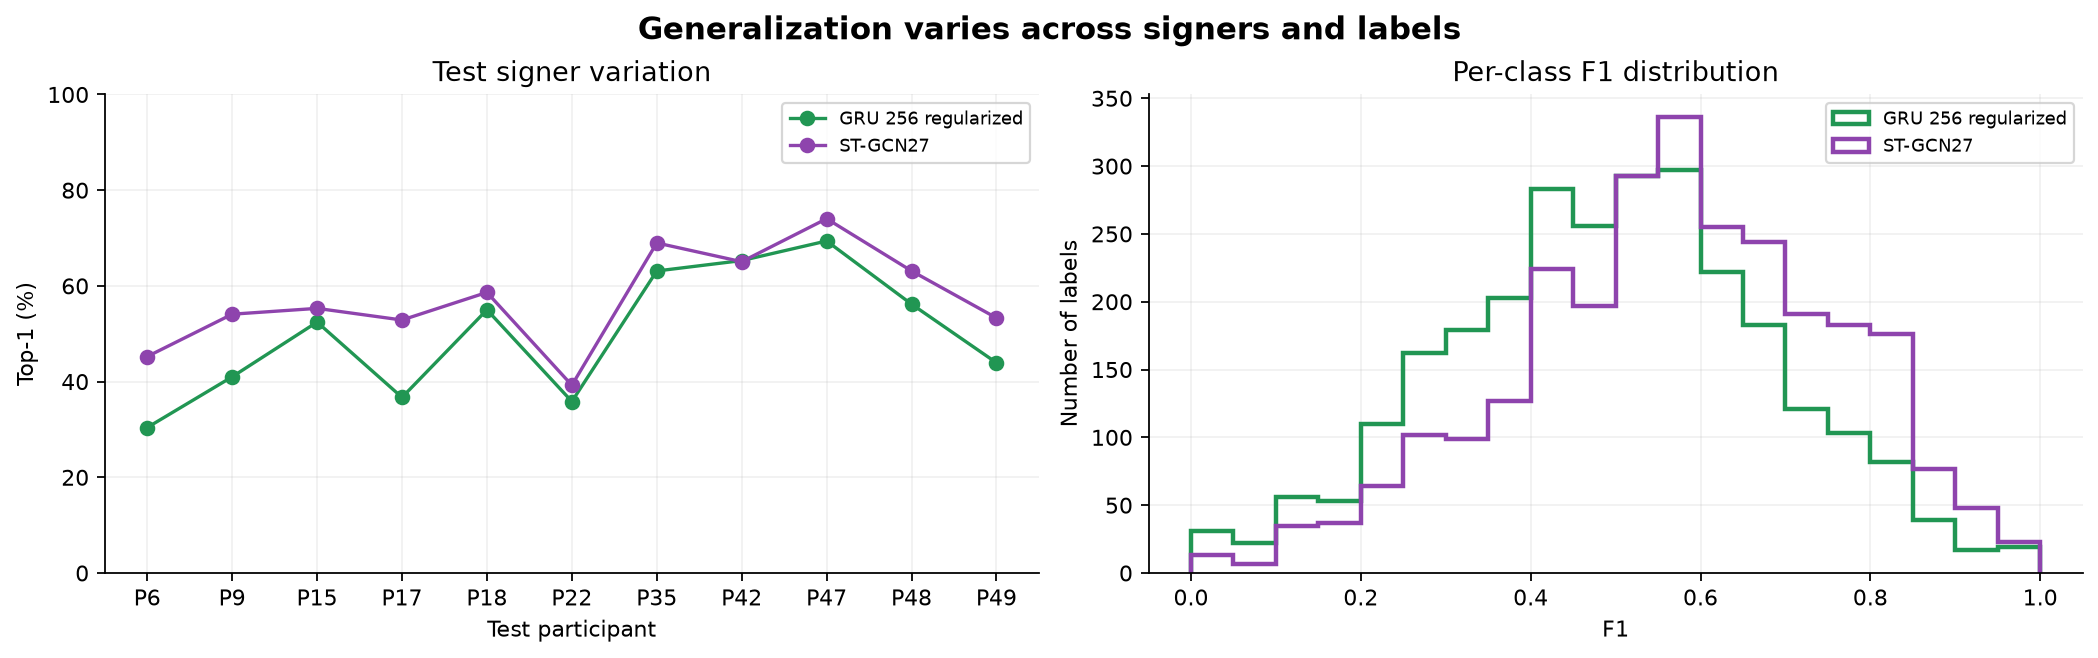

In [8]:
fig,axs=plt.subplots(1,2,figsize=(13,4))
for key,m in tested.items():
    people=sorted(m.get('per_signer',{}),key=lambda x:int(x.lstrip('P')))
    axs[0].plot(people,[m['per_signer'][p]['top1']*100 for p in people],'o-',label=m['label'],color=COLORS[key])
    axs[1].hist([r['f1'] for r in m.get('per_class',[])],bins=np.linspace(0,1,21),histtype='step',linewidth=2,label=m['label'],color=COLORS[key])
axs[0].set(title='Test signer variation',ylabel='Top-1 (%)',xlabel='Test participant',ylim=(0,100))
axs[1].set(title='Per-class F1 distribution',xlabel='F1',ylabel='Number of labels')
for ax in axs:ax.legend(fontsize=8)
finish('Generalization varies across signers and labels')

### Familiar signs: overall improvement does not apply to every class

        These are existing official test examples, not new webcam captures.
        Class sample sizes are small. HELLO and THANKYOU have fewer correct
        first guesses under ST-GCN; NO has the same number. The paired
        all-class plots below show gains and regressions across the vocabulary.

        | Label | Test clips | GRU correct | ST-GCN correct | GRU F1 | ST-GCN F1 |
| --- | --- | --- | --- | --- | --- |
| HELLO | 14 | 8/14 | 5/14 | 50.00% | 29.41% |
| THANKYOU | 12 | 9/12 | 4/12 | 43.90% | 42.11% |
| NO | 11 | 7/11 | 7/11 | 60.87% | 56.00% |

Labels with higher/lower/equal F1: 1779 887 65


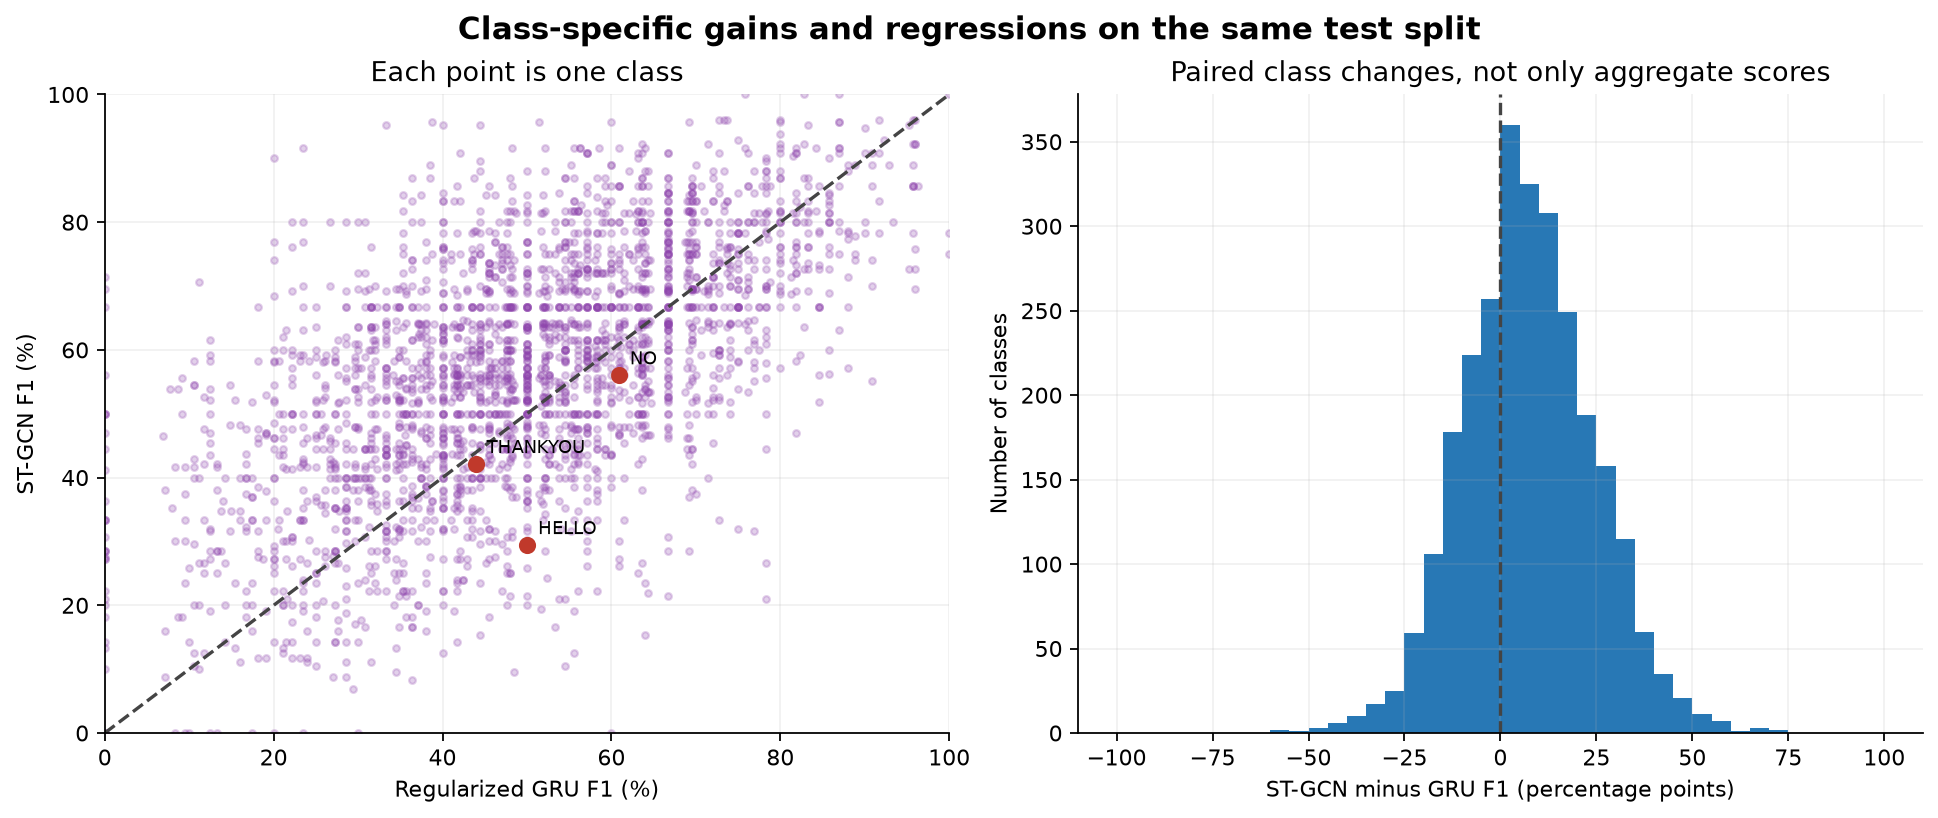

In [9]:
if 'gru_regularized' in tested and 'stgcn' in tested:
    a={r['gloss']:r for r in tested['gru_regularized']['per_class']}
    b={r['gloss']:r for r in tested['stgcn']['per_class']}
    labels=sorted(set(a)&set(b))
    old=np.array([a[name]['f1'] for name in labels])
    new=np.array([b[name]['f1'] for name in labels])
    delta=(new-old)*100
    print('Labels with higher/lower/equal F1:',int((delta>1e-9).sum()),int((delta < -1e-9).sum()),int((np.abs(delta)<=1e-9).sum()))
    fig,axs=plt.subplots(1,2,figsize=(12,5))
    axs[0].scatter(old*100,new*100,s=9,alpha=.25,color='#8e44ad')
    axs[0].plot([0,100],[0,100],'--',color='#444444')
    for name in ('HELLO','THANKYOU','NO'):
        if name in a and name in b:
            axs[0].scatter(a[name]['f1']*100,b[name]['f1']*100,s=45,color='#c0392b')
            axs[0].annotate(name,(a[name]['f1']*100,b[name]['f1']*100),xytext=(5,5),textcoords='offset points',fontsize=8)
    axs[0].set(xlabel='Regularized GRU F1 (%)',ylabel='ST-GCN F1 (%)',xlim=(0,100),ylim=(0,100),title='Each point is one class')
    axs[1].hist(delta,bins=np.linspace(-100,100,41),color='#2878b5')
    axs[1].axvline(0,ls='--',color='#444444')
    axs[1].set(xlabel='ST-GCN minus GRU F1 (percentage points)',ylabel='Number of classes',title='Paired class changes, not only aggregate scores')
    finish('Class-specific gains and regressions on the same test split')
else:
    print('Paired class comparison awaits completed ST-GCN test results.')

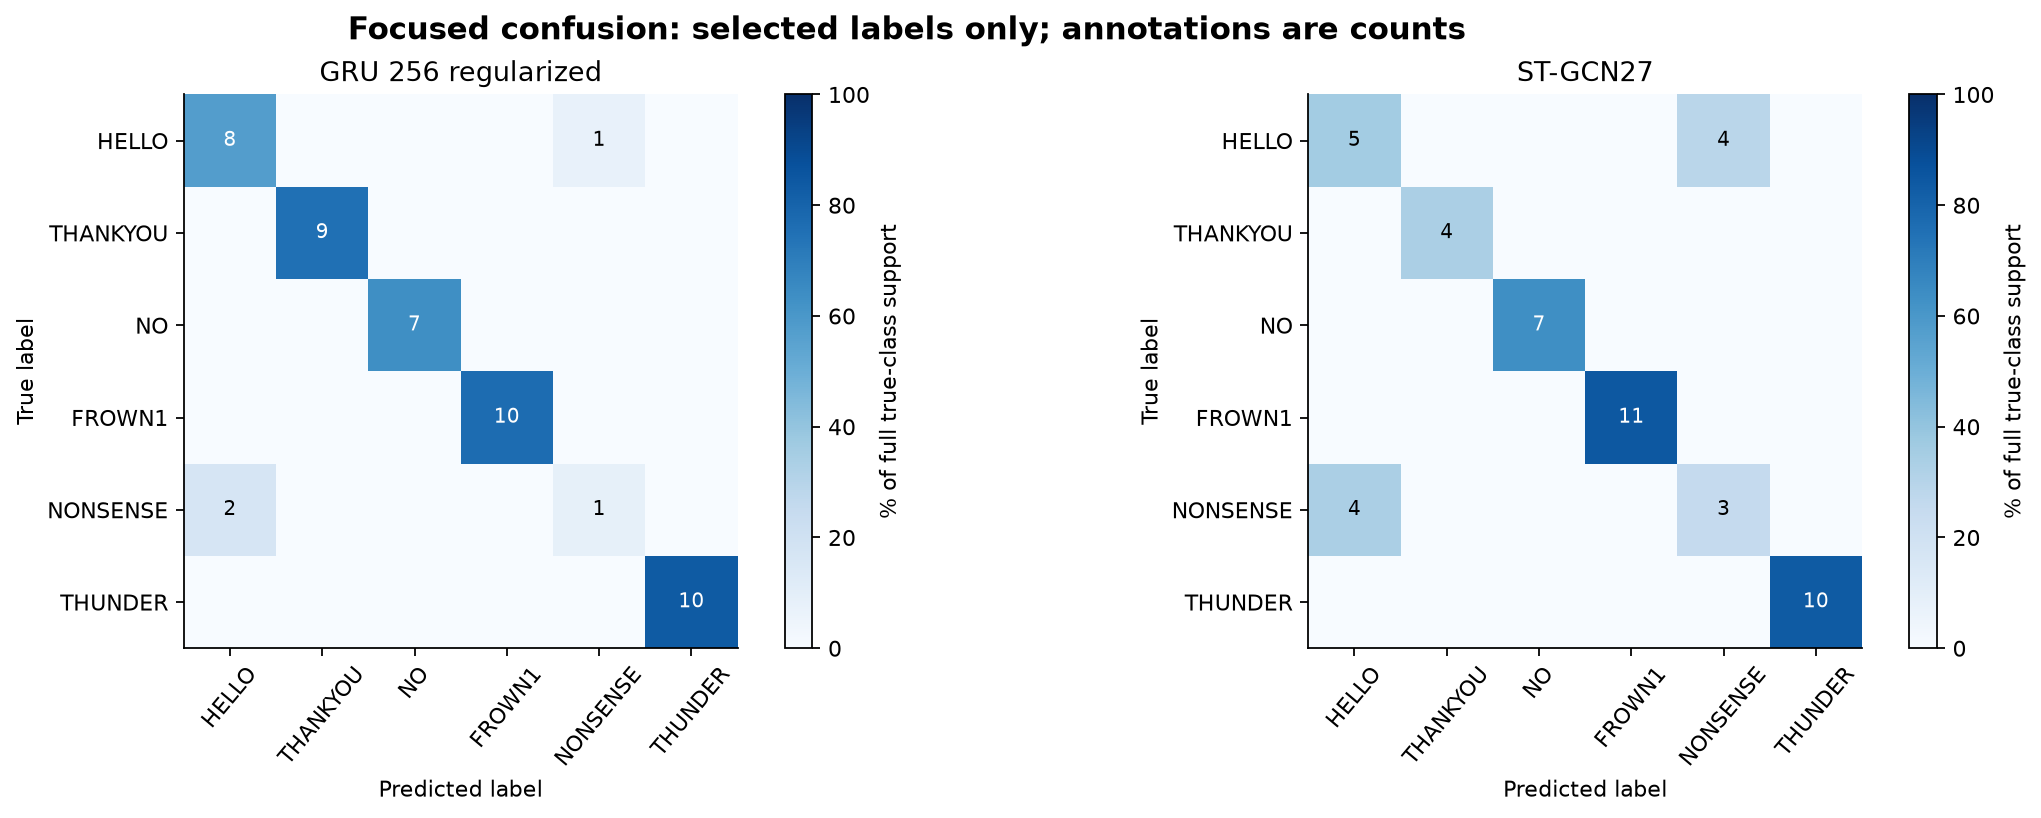

In [10]:
fig,axs=plt.subplots(1,len(tested),figsize=(7*len(tested),5),squeeze=False)
for ax,(key,m) in zip(axs.flat,tested.items()):
    c=m['focused_confusion'];counts=np.array(c['counts']);support=np.array(c['full_row_support'])
    percentages=np.divide(counts,support[:,None],out=np.zeros_like(counts,dtype=float),where=support[:,None]>0)*100
    image=ax.imshow(percentages,vmin=0,vmax=100,cmap='Blues')
    ax.set(xticks=range(len(c['labels'])),yticks=range(len(c['labels'])),xticklabels=c['labels'],yticklabels=c['labels'],xlabel='Predicted label',ylabel='True label',title=m['label'])
    ax.tick_params(axis='x',rotation=50);ax.grid(False)
    for row in range(len(counts)):
        for col in range(len(counts)):
            if counts[row,col]:ax.text(col,row,str(counts[row,col]),ha='center',va='center',color='white' if percentages[row,col]>50 else 'black',fontsize=9)
    fig.colorbar(image,ax=ax,label='% of full true-class support')
finish('Focused confusion: selected labels only; annotations are counts')

The focused matrix omits predictions outside the displayed columns. Its row
    percentages use **full class support**, so displayed rows need not sum to
    100%. This is not the complete 2,731×2,731 confusion matrix.

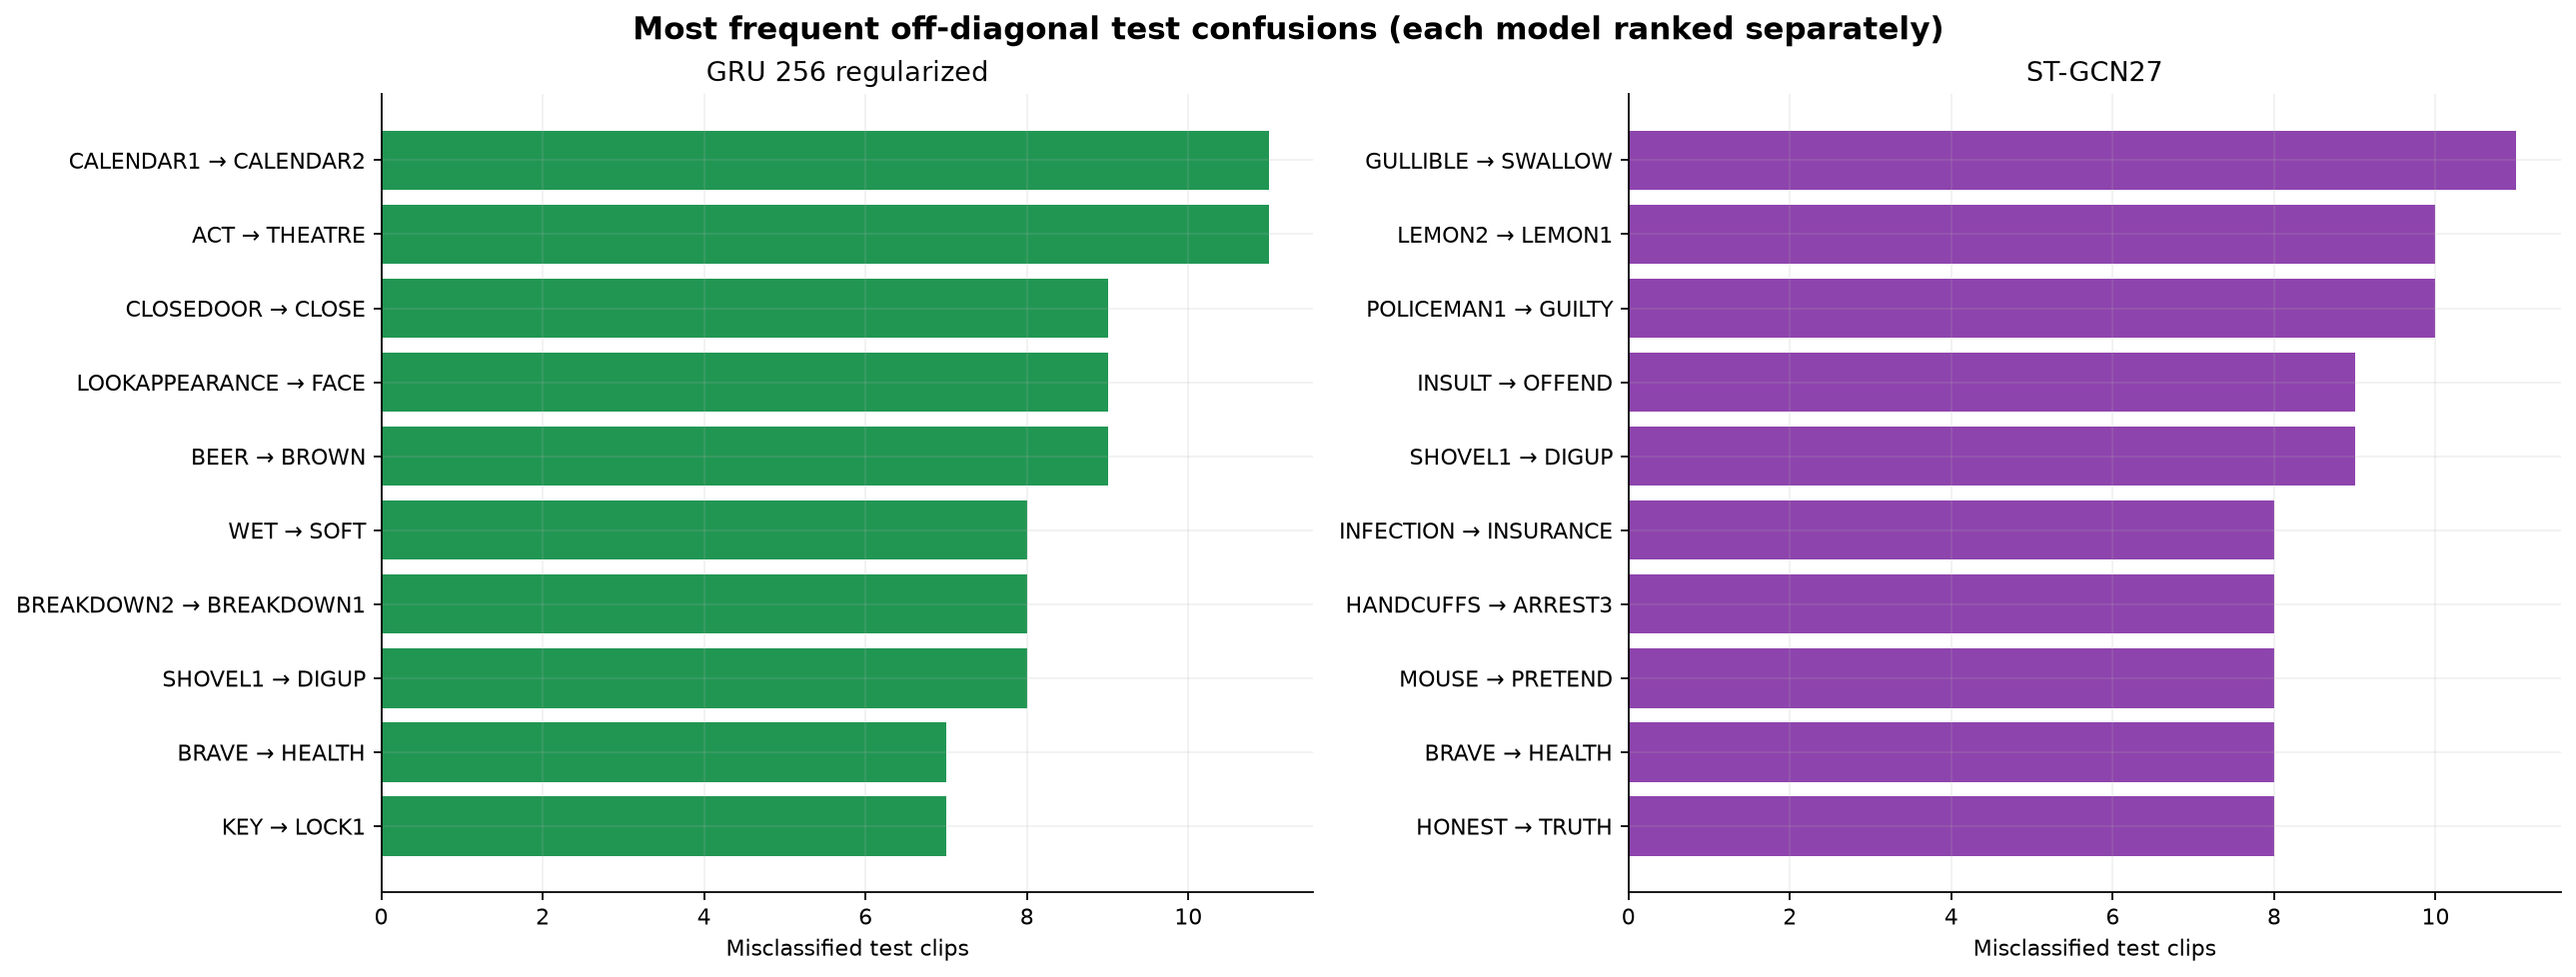

In [11]:
fig,axs=plt.subplots(1,len(tested),figsize=(8*len(tested),6),squeeze=False)
for ax,(key,m) in zip(axs.flat,tested.items()):
    pairs=list(reversed(m['top_confusions'][:10]))
    ax.barh([p['true']+' → '+p['predicted'] for p in pairs],[p['count'] for p in pairs],color=COLORS[key])
    ax.set(title=m['label'],xlabel='Misclassified test clips')
finish('Most frequent off-diagonal test confusions (each model ranked separately)')

## 6. Resource cost and learning-rate schedules

    Timings are the stored epoch measurements for this machine. Ongoing-run
    averages are preliminary; model initialization, data verification and total
    wall time have different scopes. Parameter count is not an accuracy metric.
    GPU tensor allocation excludes other device/driver allocations.

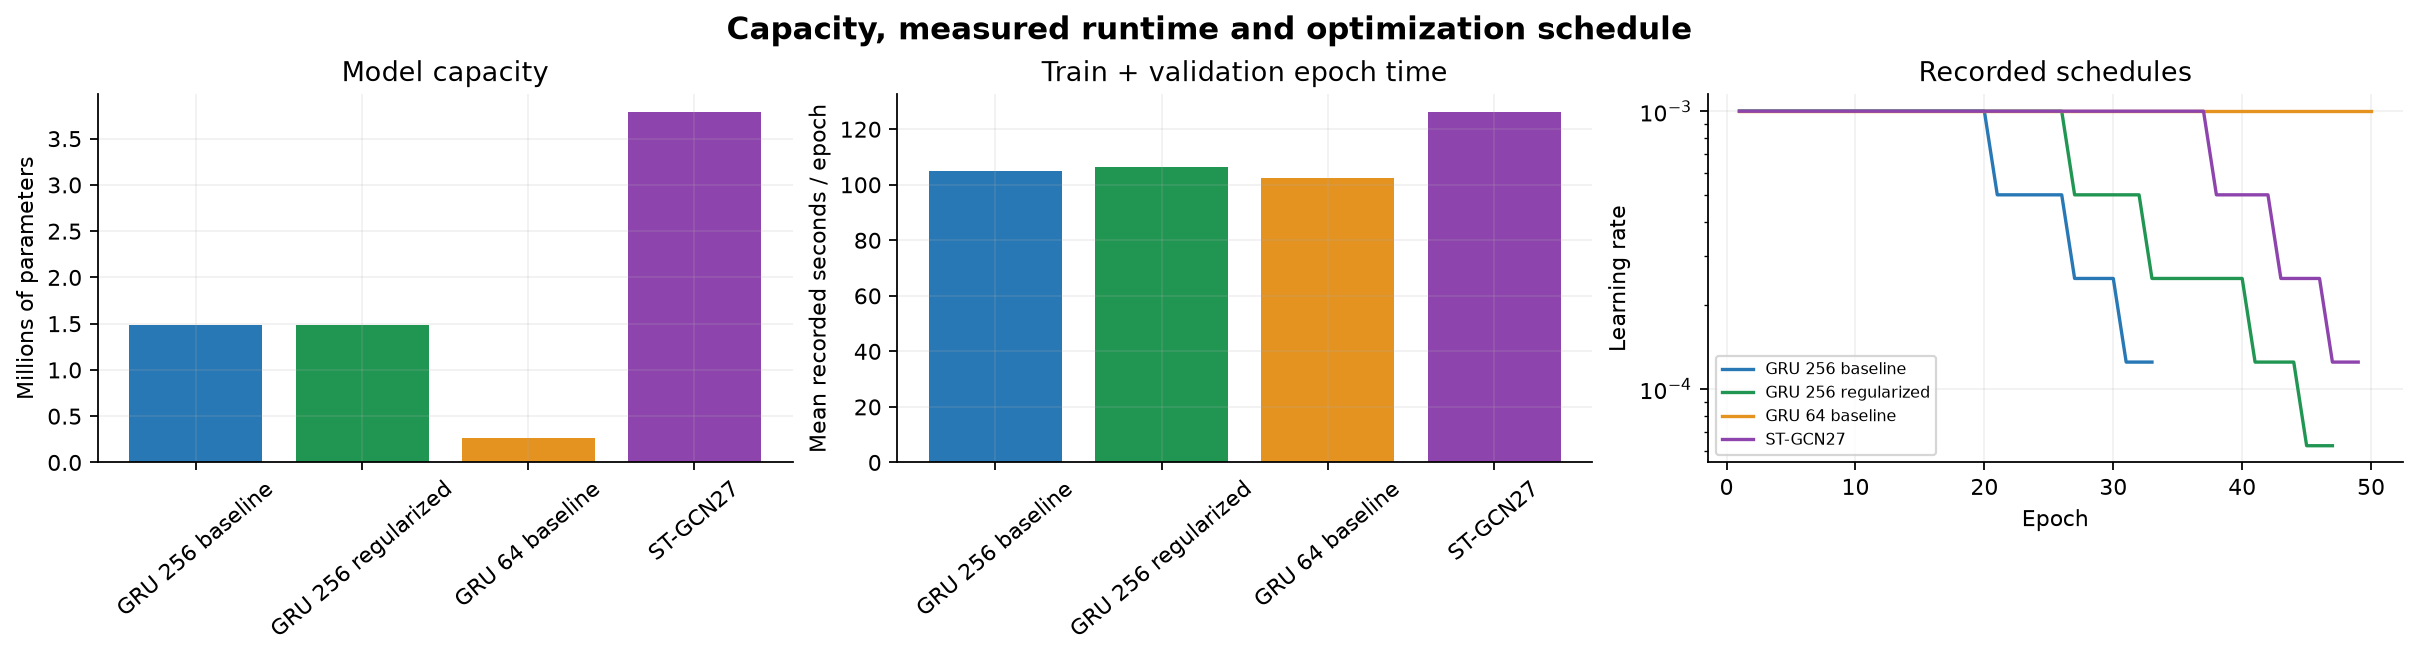

In [12]:
keys=list(M);fig,axs=plt.subplots(1,3,figsize=(15,4))
names=[M[k]['label'] for k in keys]
axs[0].bar(names,[M[k]['parameters']/1e6 for k in keys],color=[COLORS[k] for k in keys])
axs[0].set(ylabel='Millions of parameters',title='Model capacity')
axs[1].bar(names,[np.mean([r['seconds'] for r in M[k]['history']]) for k in keys],color=[COLORS[k] for k in keys])
axs[1].set(ylabel='Mean recorded seconds / epoch',title='Train + validation epoch time')
for key,m in M.items():
    axs[2].plot([r['epoch'] for r in m['history']],[r['learning_rate'] for r in m['history']],label=m['label'],color=COLORS[key])
axs[2].set(yscale='log',xlabel='Epoch',ylabel='Learning rate',title='Recorded schedules');axs[2].legend(fontsize=7)
for ax in axs[:2]:ax.tick_params(axis='x',rotation=40)
finish('Capacity, measured runtime and optimization schedule')

## 7. Interpretation and next comparisons

    - Use validation and test results for their separate purposes. Do not pick
      a new checkpoint from this test table or compare CV directly with official validation.
    - A smaller train/validation gap can indicate underfitting or incomplete
      convergence. The 64-unit result does not prove that size can never work.
    - Improvements from a combined regularization profile cannot be attributed
      to one component without a controlled ablation.
    - ST-GCN changes topology, representation, pooling and parameter count.
      Dataset performance must be followed by a separate user-attended webcam test.
    - Unknown-sign/idle rejection, calibrated scores, continuous signing and RSL
      remain unvalidated. See notebook 01 for the actual failed live checks.

    Reports and source: [GRU comparison](../docs/model-comparison-results-2026-11-10.md),
    [frozen GRU test](../docs/test-evaluation-2026-11-10.md),
    [ST-GCN protocol](../docs/stgcn-training.md),
    [investigation](../docs/recognition-investigation-2026-11-10.md).
    The companion snapshot records source hashes and dataset/checkpoint identities.
    No model or dataset is embedded in these notebooks.